
# Lab 7: Grover's Algorithm - Quantum Search and Amplitude Amplification

Welcome to Lab 7! So far, we have explored quantum communication and seen how algorithms like Deutsch-Jozsa can achieve an exponential speedup over their classical counterparts for specific oracle-based problems. Now, we turn our attention to one of the most famous and practical quantum algorithms: **Grover's search algorithm**.

Imagine searching for a specific item in a massive, unsorted database—like finding a single marked card in a deck of N cards. Classically, you would have to check the cards one by one, and on average, you'd need to look at N/2 cards. In the worst case, you'd check all N. This problem has a classical complexity of O(N).

Grover's algorithm offers a remarkable quantum solution that provides a **quadratic speedup**, allowing us to find the marked item in approximately O(√N) steps. While not an exponential speedup, this is a substantial improvement for large-scale search problems, which are common in computer science.

The algorithm works through a clever process called **amplitude amplification**. It starts by placing all qubits into an equal superposition, representing every possible item in the database simultaneously. Then, it uses two key operations repeatedly:
1.  A **quantum oracle** that "marks" the solution state by flipping its phase (multiplying its amplitude by -1).
2.  A **diffusion operator** that inverts all amplitudes about the average, effectively increasing the amplitude of the marked state while decreasing the others.

By iterating these two steps, the probability of measuring the correct answer is amplified close to 1.

In this lab, we will:
*   Implement the full Grover's search algorithm from the ground up.
*   Define a quantum "oracle" using a unitary matrix that recognizes and marks one or more winning states in the search space.
*   Construct the Grover diffusion operator, which is the core of the amplitude amplification process.
*   Combine the oracle and the diffusion operator to search for marked items in 2-qubit and 3-qubit systems.
*   Use the **`qasm_simulator`** to execute the algorithm and observe how the measurement outcomes are heavily biased towards the marked states, confirming the search was successful.
*   Gain hands-on experience with one of the cornerstone algorithms in quantum computing and witness the power of amplitude amplification.

Let's explore how quantum mechanics can help us find a needle in a haystack, quadratically faster than ever before.

In [ ]:
%pip install qiskit qiskit-aer matplotlib

In [ ]:
import qiskit
from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt # pi = 3.14 and square root operation
from qiskit.visualization import plot_state_city # Density Matrix plot
from qiskit.visualization import plot_state_qsphere # used for multi qubit visualisation
from qiskit.visualization import plot_bloch_multivector # Plotting the Bloch Sphere for Single Qubits
from qiskit.visualization import plot_histogram # 2D Histogram Plotting
import numpy as np # Numerical Python Library
from qiskit.quantum_info import Operator
from qiskit.circuit.library import ZGate


## Making a 2 Qubit Grover's Oracle marking |01> State

It is important to note that the Operator function uses our ordering system, therefore when visualizing our probability histograms, we do not need to reverse the ordering of the qubits.

Experiment by marking the other states as well - |00>, |10> and |11>

In [ ]:
U = Operator([[1,0,0,0], [0,-1,0,0], [0,0,1,0], [0,0,0,1]])

In [ ]:
print(U)

Operator([[ 1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j],
          [ 0.+0.j, -1.+0.j,  0.+0.j,  0.+0.j],
          [ 0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  1.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))


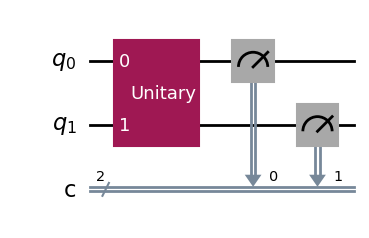

In [ ]:
qr = QuantumRegister(2, 'q')
cr = ClassicalRegister(2, 'c')

qcirc = QuantumCircuit(2, 2, name = 'qc')
qcirc.append(U, qr)
for i in range(len(qr)):
    qcirc.measure(qr[i], cr[i])
qcirc.draw('mpl')

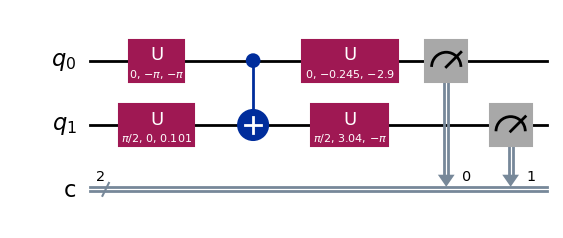

In [ ]:
# Decomposing the Oracle into unitary gates

qcirc_decompose = qcirc.decompose()
qcirc_decompose.draw('mpl')

The decomposition of a 4x4 Unitary is based on this paper - https://arxiv.org/abs/0806.4015
This paper describes the KAK decomposition method which uses optimal number of CNOT gates

## Check if Operator is Unitary

In [ ]:
U.is_unitary()

True

## Constructing our Grover's Algorithm Circuit

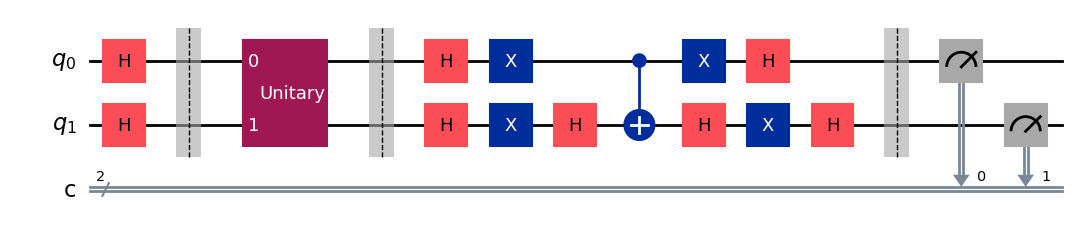

In [ ]:
# Number of Qubits
num_qubits = 2

# Defining Quantum, Classical Registers and Quantum Circuit
qr = QuantumRegister(num_qubits, 'q')
cr = ClassicalRegister(num_qubits, 'c')

qcirc = QuantumCircuit(qr, cr)

# Step 1 - Applying Hadamard Gates to all the Qubits
for i in range(num_qubits):
    qcirc.h(i)

qcirc.barrier()

# Step 2 - Applying the Grover's Oracle Operator
qcirc.append(U, qr)

qcirc.barrier()

# Step 3 - Grover's Diffusion Circuit
for qubit in range(num_qubits):
    qcirc.h(qubit)
for qubit in range(num_qubits):
    qcirc.x(qubit)
qcirc.h(num_qubits-1)
qcirc.mcx(list(range(num_qubits-1)), num_qubits-1)
qcirc.h(num_qubits-1)
for qubit in range(num_qubits):
    qcirc.x(qubit)
for qubit in range(num_qubits):
    qcirc.h(qubit)

qcirc.barrier()

# Measuring all the Qubits
qcirc.measure([0,1],[0,1])

# Visualizing the Grover's Circuit
qcirc.draw('mpl')

## Simulating 2 Qubit Grover's Circuit


Total counts are: {'01': 1000}


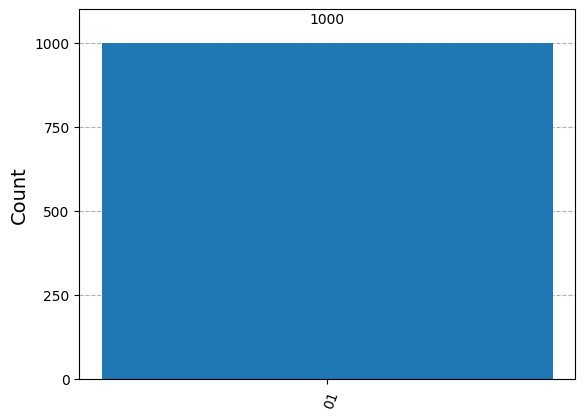

In [ ]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qcirc, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qcirc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)

As can be seen from the results we have indeed attained our marked state |01> and due to the Operator function ordering, we do not need to reverse the ordering of the qubits here. We get the exact ordering which we want.

## Making a 3 Qubit Grover's Oracle marking |101> and |110> States

Experiment with the code by marking different 2 states. If you mark 3 states together then you will observe that the algorithm is able to find the 3 states with higher probabilities in only 1 iteration of oracle+diffusion. Experiment marking any 3 states as well!

If you mark 4 or more states then, let's say you mark all the states negative except the |000> state, the you will find that the algorithm actually takes the |000> as the marked state and gives it highest probability of occurence.

In [ ]:
U_3 = Operator([[1,0,0,0,0,0,0,0],
                [0,1,0,0,0,0,0,0],
                [0,0,1,0,0,0,0,0],
                [0,0,0,1,0,0,0,0],
                [0,0,0,0,1,0,0,0],
                [0,0,0,0,0,-1,0,0],
                [0,0,0,0,0,0,-1,0],
                [0,0,0,0,0,0,0,1]])

In [ ]:
print(U_3)

Operator([[ 1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j, -1.+0.j,  0.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j, -1.+0.j,
            0.+0.j],
          [ 0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,  0.+0.j,
            1.+0.j]],
         input_dims=(2, 2, 2), output_dims=(2, 2, 2))


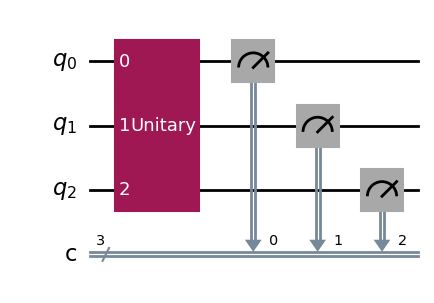

In [ ]:
qr = QuantumRegister(3, 'q')
cr = ClassicalRegister(3, 'c')

qcirc = QuantumCircuit(qr, cr)
qcirc.append(U_3, qr)
for i in range(len(qr)):
    qcirc.measure(qr[i], cr[i])
qcirc.draw('mpl')

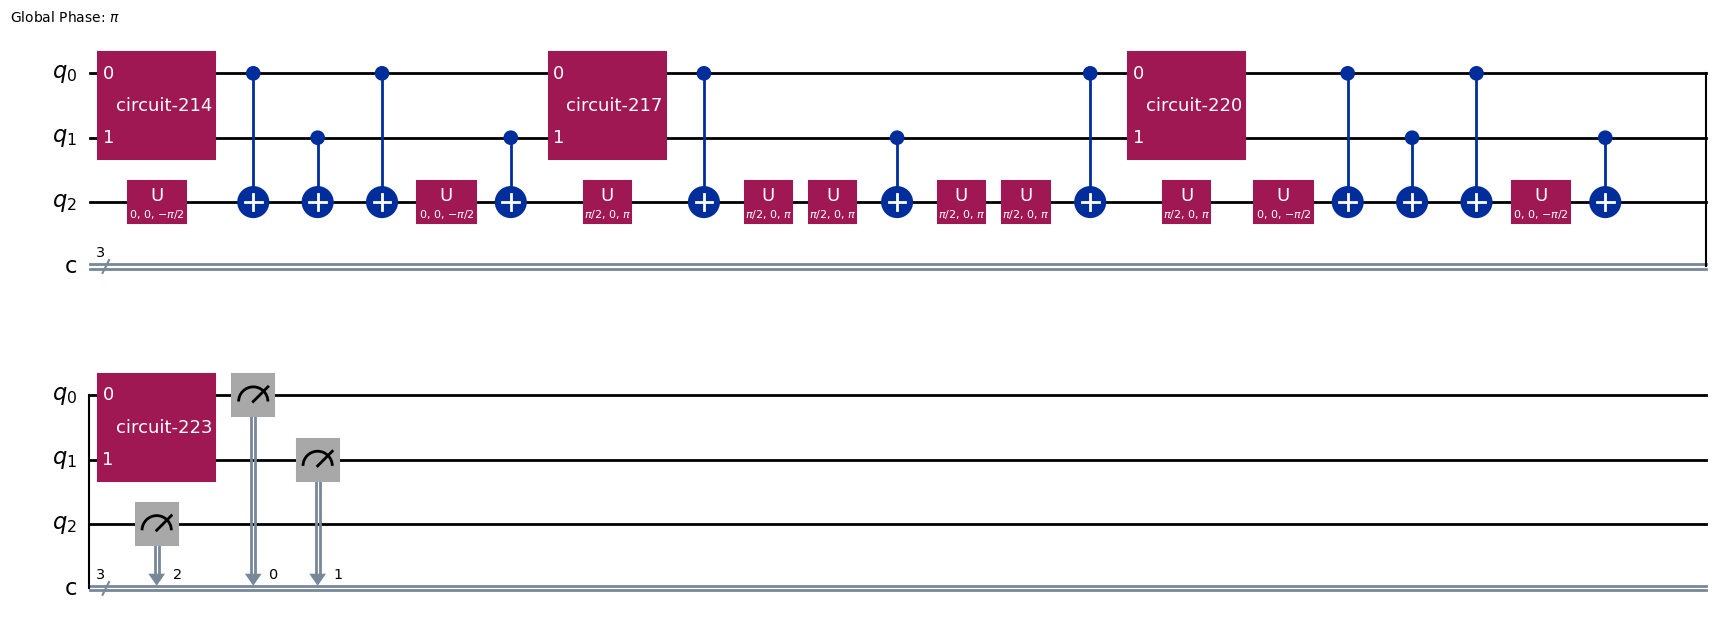

In [ ]:
# Decomposing the Oracle into unitary gates

qcirc_decompose = qcirc.decompose()
qcirc_decompose.draw('mpl')

For the decomposition of unitaries above 4x4, the isometry class from Qiskit is utilized which is implemented based on this paper - https://arxiv.org/abs/1501.06911
The paper describes a method which is able to achieve a theoretical lower bound on the number of CNOT gates used.

## Check if U_3 is Unitary


In [ ]:
U_3.is_unitary()

True

## Constructing our Grover's Algorithm Circuit

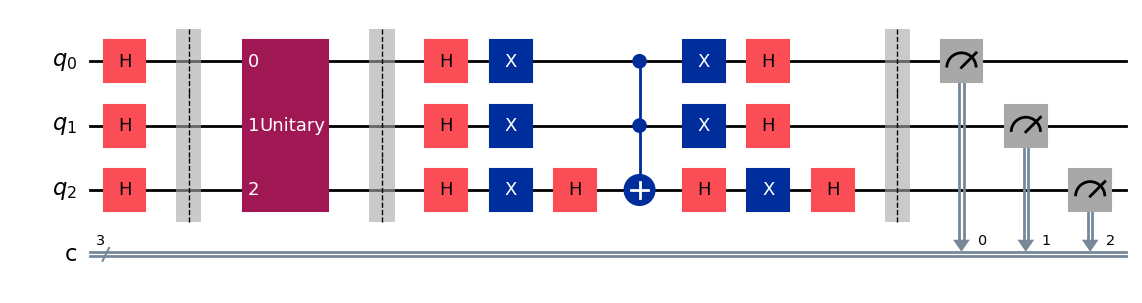

In [ ]:
# Number of Qubits
num_qubits = 3

# Defining Quantum, Classical Registers and Quantum Circuit
qr = QuantumRegister(num_qubits, 'q')
cr = ClassicalRegister(num_qubits, 'c')

qcirc = QuantumCircuit(qr, cr)

# Step 1 - Applying Hadamard Gates to all the Qubits
for i in range(num_qubits):
    qcirc.h(i)

qcirc.barrier()

# Step 2 - Applying the Grover's Oracle Operator
qcirc.append(U_3, qr)

qcirc.barrier()

# Step 3 - Grover's Diffusion Circuit
for qubit in range(num_qubits):
    qcirc.h(qubit)
for qubit in range(num_qubits):
    qcirc.x(qubit)
qcirc.h(num_qubits-1)
qcirc.mcx(list(range(num_qubits-1)), num_qubits-1)
qcirc.h(num_qubits-1)
for qubit in range(num_qubits):
    qcirc.x(qubit)
for qubit in range(num_qubits):
    qcirc.h(qubit)

qcirc.barrier()

# Measuring all the Qubits
qcirc.measure([0,1,2],[0,1,2])

# Visualizing the Grover's Circuit
qcirc.draw('mpl')

## Simulating 3 Qubit Grover's Circuit


Total counts are: {'101': 509, '110': 491}


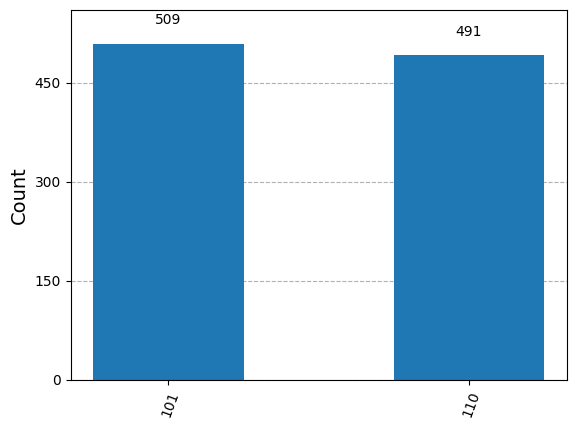

In [ ]:
# Use Aer's qasm_simulator
backend = Aer.get_backend('qasm_simulator')

transpiled_qc = transpile(qcirc, backend)

# Execute the circuit on the qasm simulator
job = backend.run(transpiled_qc, shots=1000)

# Grab results from the job
result = job.result()

# Returns counts
counts = result.get_counts(qcirc)
print("\nTotal counts are:",counts)

# Plot a histogram
plot_histogram(counts)